# Flower Classification: Iris Dataset

In this notebook, we will:
1. Load and explore the Iris dataset.
2. Visualize feature pairs.
3. Train and compare Logistic Regression and Decision Tree classifiers.
4. Evaluate models using confusion matrices.
5. Build a helper interface/function to predict class labels for new custom inputs.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define columns based on iris.names specification
columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

# Load the dataset
df = pd.read_csv('/content/iris.data', names=columns, header=None)

# Display basic information and first few rows
print("Dataset Shape:", df.shape)
print("\nDataset Summary Info:")
display(df.info())
print("\nFirst 5 rows:")
display(df.head())
print("\nClass Distribution:")
print(df['species'].value_counts())

Dataset Shape: (150, 5)

Dataset Summary Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


None


First 5 rows:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa



Class Distribution:
species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


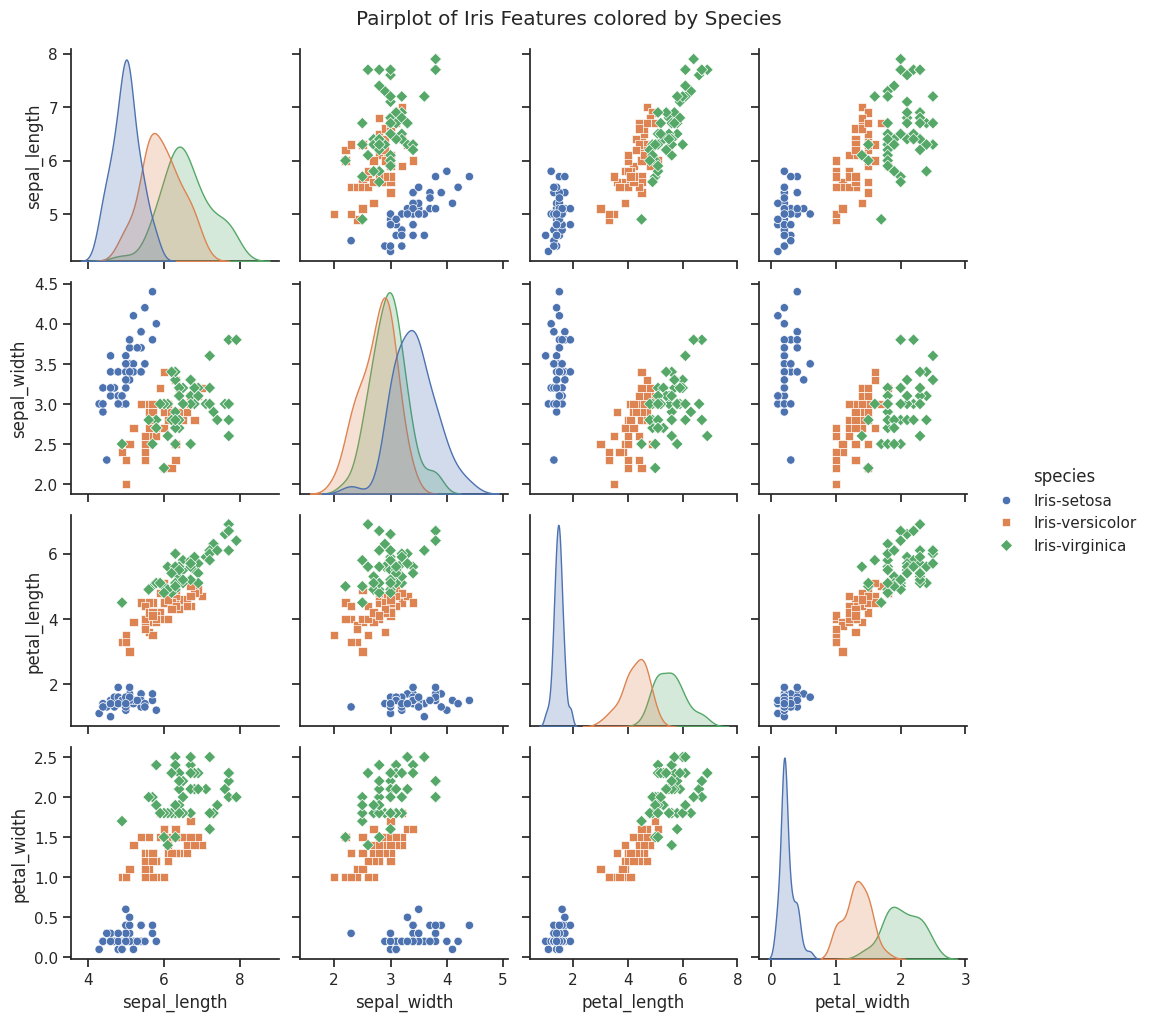

In [11]:
# Perform Exploratory Data Analysis (EDA) - Pairplot to visualize feature interactions
sns.set_theme(style="ticks")
g = sns.pairplot(df, hue="species", diag_kind="kde", markers=["o", "s", "D"])
g.fig.suptitle("Pairplot of Iris Features colored by Species", y=1.02)
plt.show()

## Model Training and Comparison

We will now prepare the features and labels, perform a train-test split, train a **Logistic Regression** classifier and a **Decision Tree** classifier, and compare their performance.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Split features and target label
X = df.drop(columns=['species'])
y = df['species']

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 1. Train Logistic Regression
lr_model = LogisticRegression(max_iter=200, random_state=42)
lr_model.fit(X_train, y_train)

# 2. Train Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Predict and compare accuracy
y_pred_lr = lr_model.predict(X_test)
y_pred_dt = dt_model.predict(X_test)

print(f"Logistic Regression Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Decision Tree Accuracy:        {accuracy_score(y_test, y_pred_dt):.4f}")

Logistic Regression Accuracy: 0.9333
Decision Tree Accuracy:        0.9333


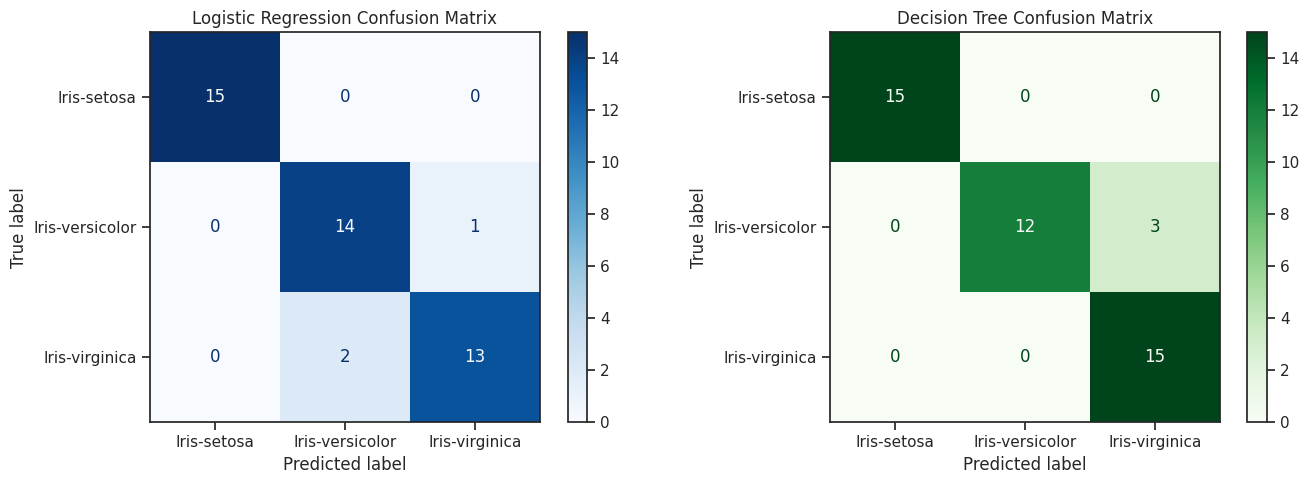

In [13]:
# Plot Confusion Matrices for both models side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_estimator(
    lr_model, X_test, y_test, cmap='Blues', ax=axes[0]
)
axes[0].set_title("Logistic Regression Confusion Matrix")

ConfusionMatrixDisplay.from_estimator(
    dt_model, X_test, y_test, cmap='Greens', ax=axes[1]
)
axes[1].set_title("Decision Tree Confusion Matrix")

plt.tight_layout()
plt.show()

## Custom Input Prediction

We will create a function that allows users to input their own custom measurement values and get a real-time prediction using our trained models.

In [14]:
def predict_species(sepal_l, sepal_w, petal_l, petal_w, model=lr_model):
    """
    Accepts custom measurements and uses a trained model to predict the species.
    """
    input_data = pd.DataFrame([[sepal_l, sepal_w, petal_l, petal_w]], columns=columns[:-1])
    prediction = model.predict(input_data)[0]
    probabilities = model.predict_proba(input_data)[0] if hasattr(model, "predict_proba") else None

    print(f"Predicted Species: {prediction}")
    if probabilities is not None:
        print("Prediction Probabilities:")
        for cls, prob in zip(model.classes_, probabilities):
            print(f"  - {cls}: {prob*100:.2f}%")

# Example prediction with custom sample values
print("Example Prediction on custom values [5.1, 3.5, 1.4, 0.2]:")
predict_species(5.1, 3.5, 1.4, 0.2)

Example Prediction on custom values [5.1, 3.5, 1.4, 0.2]:
Predicted Species: Iris-setosa
Prediction Probabilities:
  - Iris-setosa: 97.70%
  - Iris-versicolor: 2.30%
  - Iris-virginica: 0.00%
